# EDA Note

There are business question that I'm trying to find answer

Q: Do late delivereis drive bad reviews at Olist, and how can we fix this problem ?

**Setup**

Loads the SQL extension and connects to the Olist database.

In [1]:
%load_ext sql
%sql duckdb:///../data/olist.duckdb
%config SqlMagic.displaylimit = 30
import matplotlib.pyplot as plt

Connecting to 'duckdb:///../data/olist.duckdb'

In [ ]:
%%sql

SELECT
    MIN(days_late)                 AS min_days_late,
    QUANTILE_CONT(days_late, 0.25) AS p25,
    MEDIAN(days_late)              AS median,
    QUANTILE_CONT(days_late, 0.75) AS p75,
    MAX(days_late)                 AS max_days_late
FROM orders_clean

In [36]:
%%sql

CREATE OR REPLACE VIEW orders_enriched AS
WITH main_cat AS (
    SELECT order_id, category AS main_category
    FROM (
        SELECT order_id, category, SUM(price) AS cat_revenue
        FROM items_clean
        GROUP BY order_id, category
    )
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY order_id
        ORDER BY cat_revenue DESC, category
    ) = 1
)
SELECT
    o.*,
    m.main_category,
    DATE_TRUNC('month', o.order_purchase_timestamp)::DATE AS purchase_month,
    CASE
        WHEN o.days_late <= -8 THEN '1. 8+ days early'
        WHEN o.days_late <= -1 THEN '2. 1-7 days early'
        WHEN o.days_late =   0 THEN '3. On the estimated day'
        WHEN o.days_late <=  3 THEN '4. 1-3 days late'
        WHEN o.days_late <=  7 THEN '5. 4-7 days late'
        WHEN o.days_late <= 14 THEN '6. 8-14 days late'
        ELSE                        '7. 15+ days late'
    END AS delivery_bucket,
    o.review_score <= 2 AS is_bad_review
FROM orders_clean AS o
JOIN main_cat AS m USING (order_id)


Running query in 'duckdb:///../data/olist.duckdb'

Count


In [ ]:
%%sql

SELECT
    COUNT(*)                 AS rows,
    COUNT(DISTINCT order_id) AS orders
FROM orders_enriched

Running query in 'duckdb:///../data/olist.duckdb'

rows,orders
95560,95560


In [39]:
%%sql

SELECT
    delivery_bucket,
    COUNT(*)                                AS orders,
    ROUND(100 * AVG(is_bad_review::INT), 1) AS bad_review_pct
FROM orders_enriched
GROUP BY delivery_bucket
ORDER BY delivery_bucket

Running query in 'duckdb:///../data/olist.duckdb'

delivery_bucket,orders,bad_review_pct
1. 8+ days early,70673,9.0
2. 1-7 days early,17229,10.2
3. On the estimated day,1280,12.4
4. 1-3 days late,1851,32.1
5. 4-7 days late,1748,67.7
6. 8-14 days late,1446,80.2
7. 15+ days late,1333,78.3


In [45]:
%%sql
SELECT *
FROM orders_enriched
LIMIT 3

Running query in 'duckdb:///../data/olist.duckdb'

order_id,customer_unique_id,customer_state,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,days_late,is_late,review_score,n_items,revenue,freight,main_category,purchase_month,delivery_bucket,is_bad_review
e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,SP,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18 00:00:00,8,-8,False,4,1,29.99,8.72,housewares,2017-10-01,1. 8+ days early,False
53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,BA,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13 00:00:00,14,-6,False,4,1,118.7,22.76,perfumery,2018-07-01,2. 1-7 days early,False
47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,GO,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04 00:00:00,9,-18,False,5,1,159.9,19.22,auto,2018-08-01,1. 8+ days early,False


### Q1. How did orders and revenue change over time

In [ ]:
%%sql monthly <<

SELECT 
    purchase_month,
    COUNT(*)               AS orders,
    ROUND(SUM(revenue), 0) AS revenue
FROM orders_enriched
GROUP BY purchase_month
ORDER BY purchase_month

Running query in 'duckdb:///../data/olist.duckdb'

,purchase_month,orders,revenue
10,2017-11-01,7237,978646.0
12,2018-01-01,7013,915587.0
14,2018-03-01,6948,943359.0


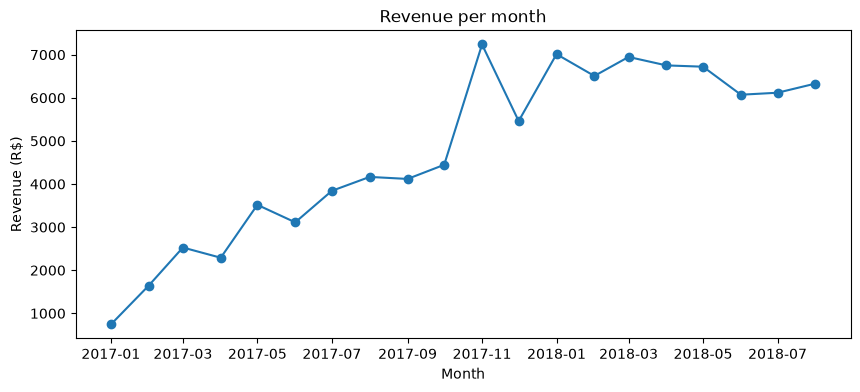

In [132]:
df = monthly.DataFrame()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df["purchase_month"], df["orders"], marker="o")
ax.set_title("Revenue per month")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (R$)")
fig.savefig("../images/01_revenue_by_month.png", dpi=150, bbox_inches = "tight")
df.sort_values("orders", ascending=False).head(3)

**[Answer]:** Overall order and revenue gradually increase through 2017 to a peak about around November 2017 and followed by January 2018. The reason is possibly due to holiday season like black friday, as well as new years.

### Q2. How often are order late, and is it getting better ?

In [88]:
%%sql monthly_2 <<

SELECT 
    purchase_month,
    COUNT(*)                          AS orders,
    ROUND(100 * AVG(is_late::INT), 1) AS late_pct
FROM orders_enriched
GROUP BY purchase_month
ORDER BY purchase_month

Running query in 'duckdb:///../data/olist.duckdb'

In [89]:
monthly_2

RuntimeError: Error running the query: (_duckdb.ResourceInUseException) Resource In Use Error: connection is busy with another call; it refuses instead of waiting, so use a separate connection from cursor()
(Background on this error at: https://sqlalche.me/e/21/e3q8)


purchase_month,orders,late_pct
2017-01-01,741,2.8
2017-02-01,1643,2.6
2017-03-01,2527,4.5
2017-04-01,2290,6.4
2017-05-01,3517,2.8
2017-06-01,3111,3.0
2017-07-01,3842,2.7
2017-08-01,4165,2.9
2017-09-01,4118,4.3
2017-10-01,4446,4.0


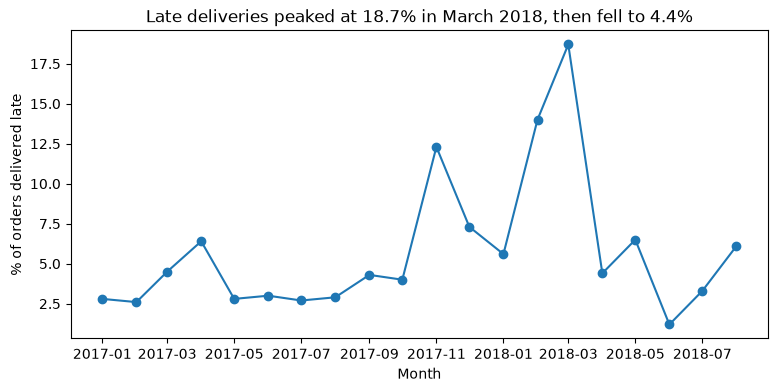

In [93]:
df = monthly_2.DataFrame()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(df["purchase_month"], df["late_pct"], marker="o")
ax.set_xlabel("Month")
ax.set_ylabel("% of orders delivered late")
ax.set_title("Late deliveries peaked at 18.7% in March 2018, then fell to 4.4%")
fig.savefig("../images/02_late_rate_by_month.png", dpi=150, bbox_inches="tight")


### Q3. Do late orders get worse reivews ?

In [113]:
%%sql q3 <<

SELECT
    is_late,
    Count(*)        AS orders,
    ROUND(AVG(review_score), 2) AS avg_score,
    ROUND(100 * AVG(is_bad_review::INT), 1) AS bad_review_pct,
    ROUND(100 * AVG((review_score = 5)::INT), 1) AS five_star_pct
FROM orders_enriched
GROUP BY is_late
ORDER BY is_late
    


Running query in 'duckdb:///../data/olist.duckdb'

In [114]:
q3

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

is_late,orders,avg_score,bad_review_pct,five_star_pct
False,89182,4.29,9.2,62.3
True,6378,2.27,62.4,16.5


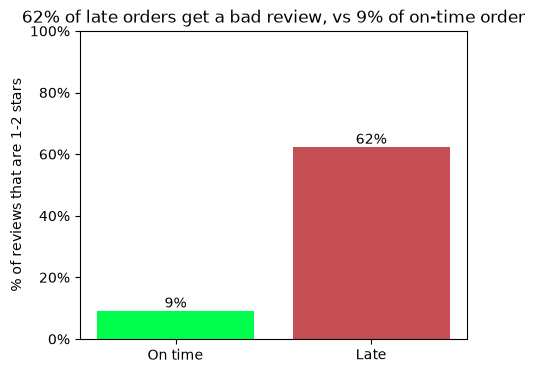

In [133]:
from matplotlib.ticker import PercentFormatter

df = q3.DataFrame().sort_values("is_late")
df["group"] = df["is_late"].map({False: "On time", True: "Late"})

fig, ax = plt.subplots(figsize = (5, 4))
ax.set_ylim(0, 100)
ax.bar(df["group"], df["bad_review_pct"], color=["#00FF4C", "#C44E52"])
ax.set_ylabel("% of reviews that are 1-2 stars")
ax.set_title("62% of late orders get a bad review, vs 9% of on-time order")
ax.yaxis.set_major_formatter(PercentFormatter())
for i, v in enumerate(df["bad_review_pct"]):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center")

fig.savefig("../images/03_bad_reviews_late_vs_on_time.png", dpi = 150, bbox_inches="tight")



### Q4. Does how late the delivery is matter ?

In [134]:
%%sql
SELECT *
FROM orders_enriched
LIMIT 3

Running query in 'duckdb:///../data/olist.duckdb'

order_id,customer_unique_id,customer_state,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,days_late,is_late,review_score,n_items,revenue,freight,main_category,purchase_month,delivery_bucket,is_bad_review
e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,SP,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18 00:00:00,8,-8,False,4,1,29.99,8.72,housewares,2017-10-01,1. 8+ days early,False
53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,BA,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13 00:00:00,14,-6,False,4,1,118.7,22.76,perfumery,2018-07-01,2. 1-7 days early,False
47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,GO,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04 00:00:00,9,-18,False,5,1,159.9,19.22,auto,2018-08-01,1. 8+ days early,False


In [142]:
%%sql q4 <<
SELECT 
delivery_bucket,
COUNT(*)                                 AS orders,
ROUND(AVG(review_score), 2)              AS average_score,
ROUND(100 * AVG(is_bad_review::INT), 1 ) AS bad_review_pct
FROM orders_enriched
GROUP BY delivery_bucket
ORDER BY delivery_bucket


Running query in 'duckdb:///../data/olist.duckdb'

In [144]:
q4

delivery_bucket,orders,average_score,bad_review_pct
1. 8+ days early,70673,4.32,9.0
2. 1-7 days early,17229,4.2,10.2
3. On the estimated day,1280,4.03,12.4
4. 1-3 days late,1851,3.29,32.1
5. 4-7 days late,1748,2.1,67.7
6. 8-14 days late,1446,1.67,80.2
7. 15+ days late,1333,1.72,78.3


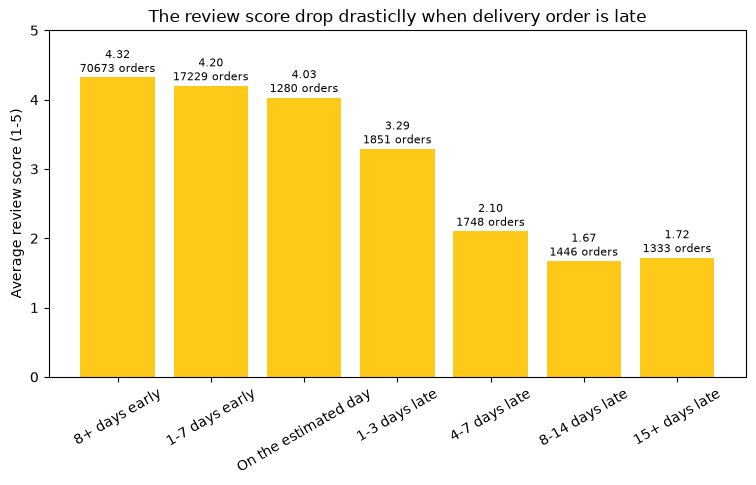

In [161]:
df = q4.DataFrame()
df["label"] = df["delivery_bucket"].str.replace(r"^\d+\.\s*", "", regex=True)
fig, ax = plt.subplots(figsize=(9,4.5))
ax.bar(df["label"], df["average_score"], color="#FFC919")
ax.set_ylim(0,5)
ax.set_ylabel("Average review score (1-5)")
ax.set_title("The review score drop drasticlly when delivery order is late")
ax.tick_params(axis="x", rotation=30)
for i, (s, n) in enumerate(zip(df["average_score"], df["orders"])):
    ax.text(i, s + 0.08, f"{s:.2f}\n{n} orders", ha="center", fontsize=8)

fig.savefig("../images/04_avg_review_score_vs_delivery_date_bucket.png", dpi=150, bbox_inches="tight")